# Fig 3: the PFC example

This notebook draws the paper's Fig 3 (`pfc_composite_rnactl`) from pre-computed numbers only.
It reads only `figures/fig3_pfc/` from the figshare item and draws it with the plot modules in
`figures/`, which are copies of the figure package's scripts. Each panel script checks its
marks against its CSV before drawing.

All fits are the release configuration (SDE path-KL, β = 1e-4).
* **(a)** The seven endpoints, as three bars:
  * ours on the full training split (mean of seeds 22, 44 and 88);
  * ours at the matched 8,000 + 8,000 nuclei (mean of seeds 22, 44 and 88);
  * uniPort on the full split (one fit). uniPort is the only competitor that reaches the full
    split.

  All three are scored on the same 8,000 + 8,000 nuclei, the matched tier's. The PFC benchmark
  is in-sample: those are training nuclei.
* **(b)** A UMAP of the fused latent of both modalities: seed 44, 20,000 + 20,000 nuclei. Each
  type's RNA and ATAC centroids are joined.
  * Connector length is not a measure of alignment. The alignment numbers are the centroid
    cosines of Table 1, below.
  * Refitting the UMAP from the released latent gives the same coordinates on the machine that
    drew it. Elsewhere, float round-off can move a few of them by 0.001.
* **(c, d)** UMAPs of the raw RNA and ATAC inputs. They do not depend on the model. The medoids
  of the three types with the lowest cosine in Table 1 are starred.
* **(e, f)** Astrocyte maturation, on training and held-out donors: (e) the immature programme,
  which is context only, and (f) the mature programme.
  * Each cohort is rolled forward from Gestation. On each side, 300 astrocytes are drawn from
    both modalities (the mixed-modality cohort). The 100 non-astrocyte controls come from the
    RNA-only cohort.
  * The held-out side is one withheld donor per modality. Its astrocytes are 285 RNA nuclei from
    RL2107 and 15 ATAC nuclei from RL2366. Its controls are RNA nuclei from RL2107.
  * Curves are means over seeds 22, 44 and 88. The band is ± 1 s.e.m. across seeds.
  * Rising margin, mean ± sd over seeds: +0.803 ± 0.245 on train and +0.464 ± 0.447
    held-out. The per-seed values are in `astro_rnactl_margins.csv`, shown at the end.

In [1]:
import hashlib
import os
import sys
import tempfile
from pathlib import Path

import matplotlib
import pandas as pd
from IPython.display import Image, display

# Jupyter runs a notebook with its own folder (benchmark/) as the working directory.
BENCHMARK = Path.cwd()
if not (BENCHMARK / "figures" / "plot_pfc_composite.py").is_file():
    raise RuntimeError("run this notebook from the repository's benchmark/ folder")
# The figshare folder: $MTVAE_DATA, else ../figshare next to the repository.
DATA = Path(os.environ.get("MTVAE_DATA", BENCHMARK.parent.parent / "figshare"))
FIG_DATA = DATA / "figures" / "fig3_pfc"
missing = [name for name in ["8k_vs_full_values.csv", "cell_types.csv", "umap_joint_coords.csv", "umap_raw_rna_coords.csv", "umap_raw_atac_coords.csv", "umap_markers.csv", "umap_settings.csv", "astro_mixed_panels.csv", "astro_mixed_margins.csv", "pfc_astro_panels.csv", "astro_rnactl_margins.csv"] if not (FIG_DATA / name).is_file()]
if missing:
    raise FileNotFoundError(f"figures/fig3_pfc/ lacks {missing}: set MTVAE_DATA "
                            "to the unzipped figshare folder")
# The figure files go to $MTVAE_FIG_OUT, else a new temporary folder.
OUT = Path(os.environ.get("MTVAE_FIG_OUT") or tempfile.mkdtemp(prefix="fig3_pfc_"))
sys.path.insert(0, str(BENCHMARK / "figures"))
print("matplotlib", matplotlib.__version__, "| reading", "figures/fig3_pfc/:", ", ".join(["8k_vs_full_values.csv", "cell_types.csv", "umap_joint_coords.csv", "umap_raw_rna_coords.csv", "umap_raw_atac_coords.csv", "umap_markers.csv", "umap_settings.csv", "astro_mixed_panels.csv", "astro_mixed_margins.csv", "pfc_astro_panels.csv", "astro_rnactl_margins.csv"]))

matplotlib 3.11.1 | reading figures/fig3_pfc/: 8k_vs_full_values.csv, cell_types.csv, umap_joint_coords.csv, umap_raw_rna_coords.csv, umap_raw_atac_coords.csv, umap_markers.csv, umap_settings.csv, astro_mixed_panels.csv, astro_mixed_margins.csv, pfc_astro_panels.csv, astro_rnactl_margins.csv


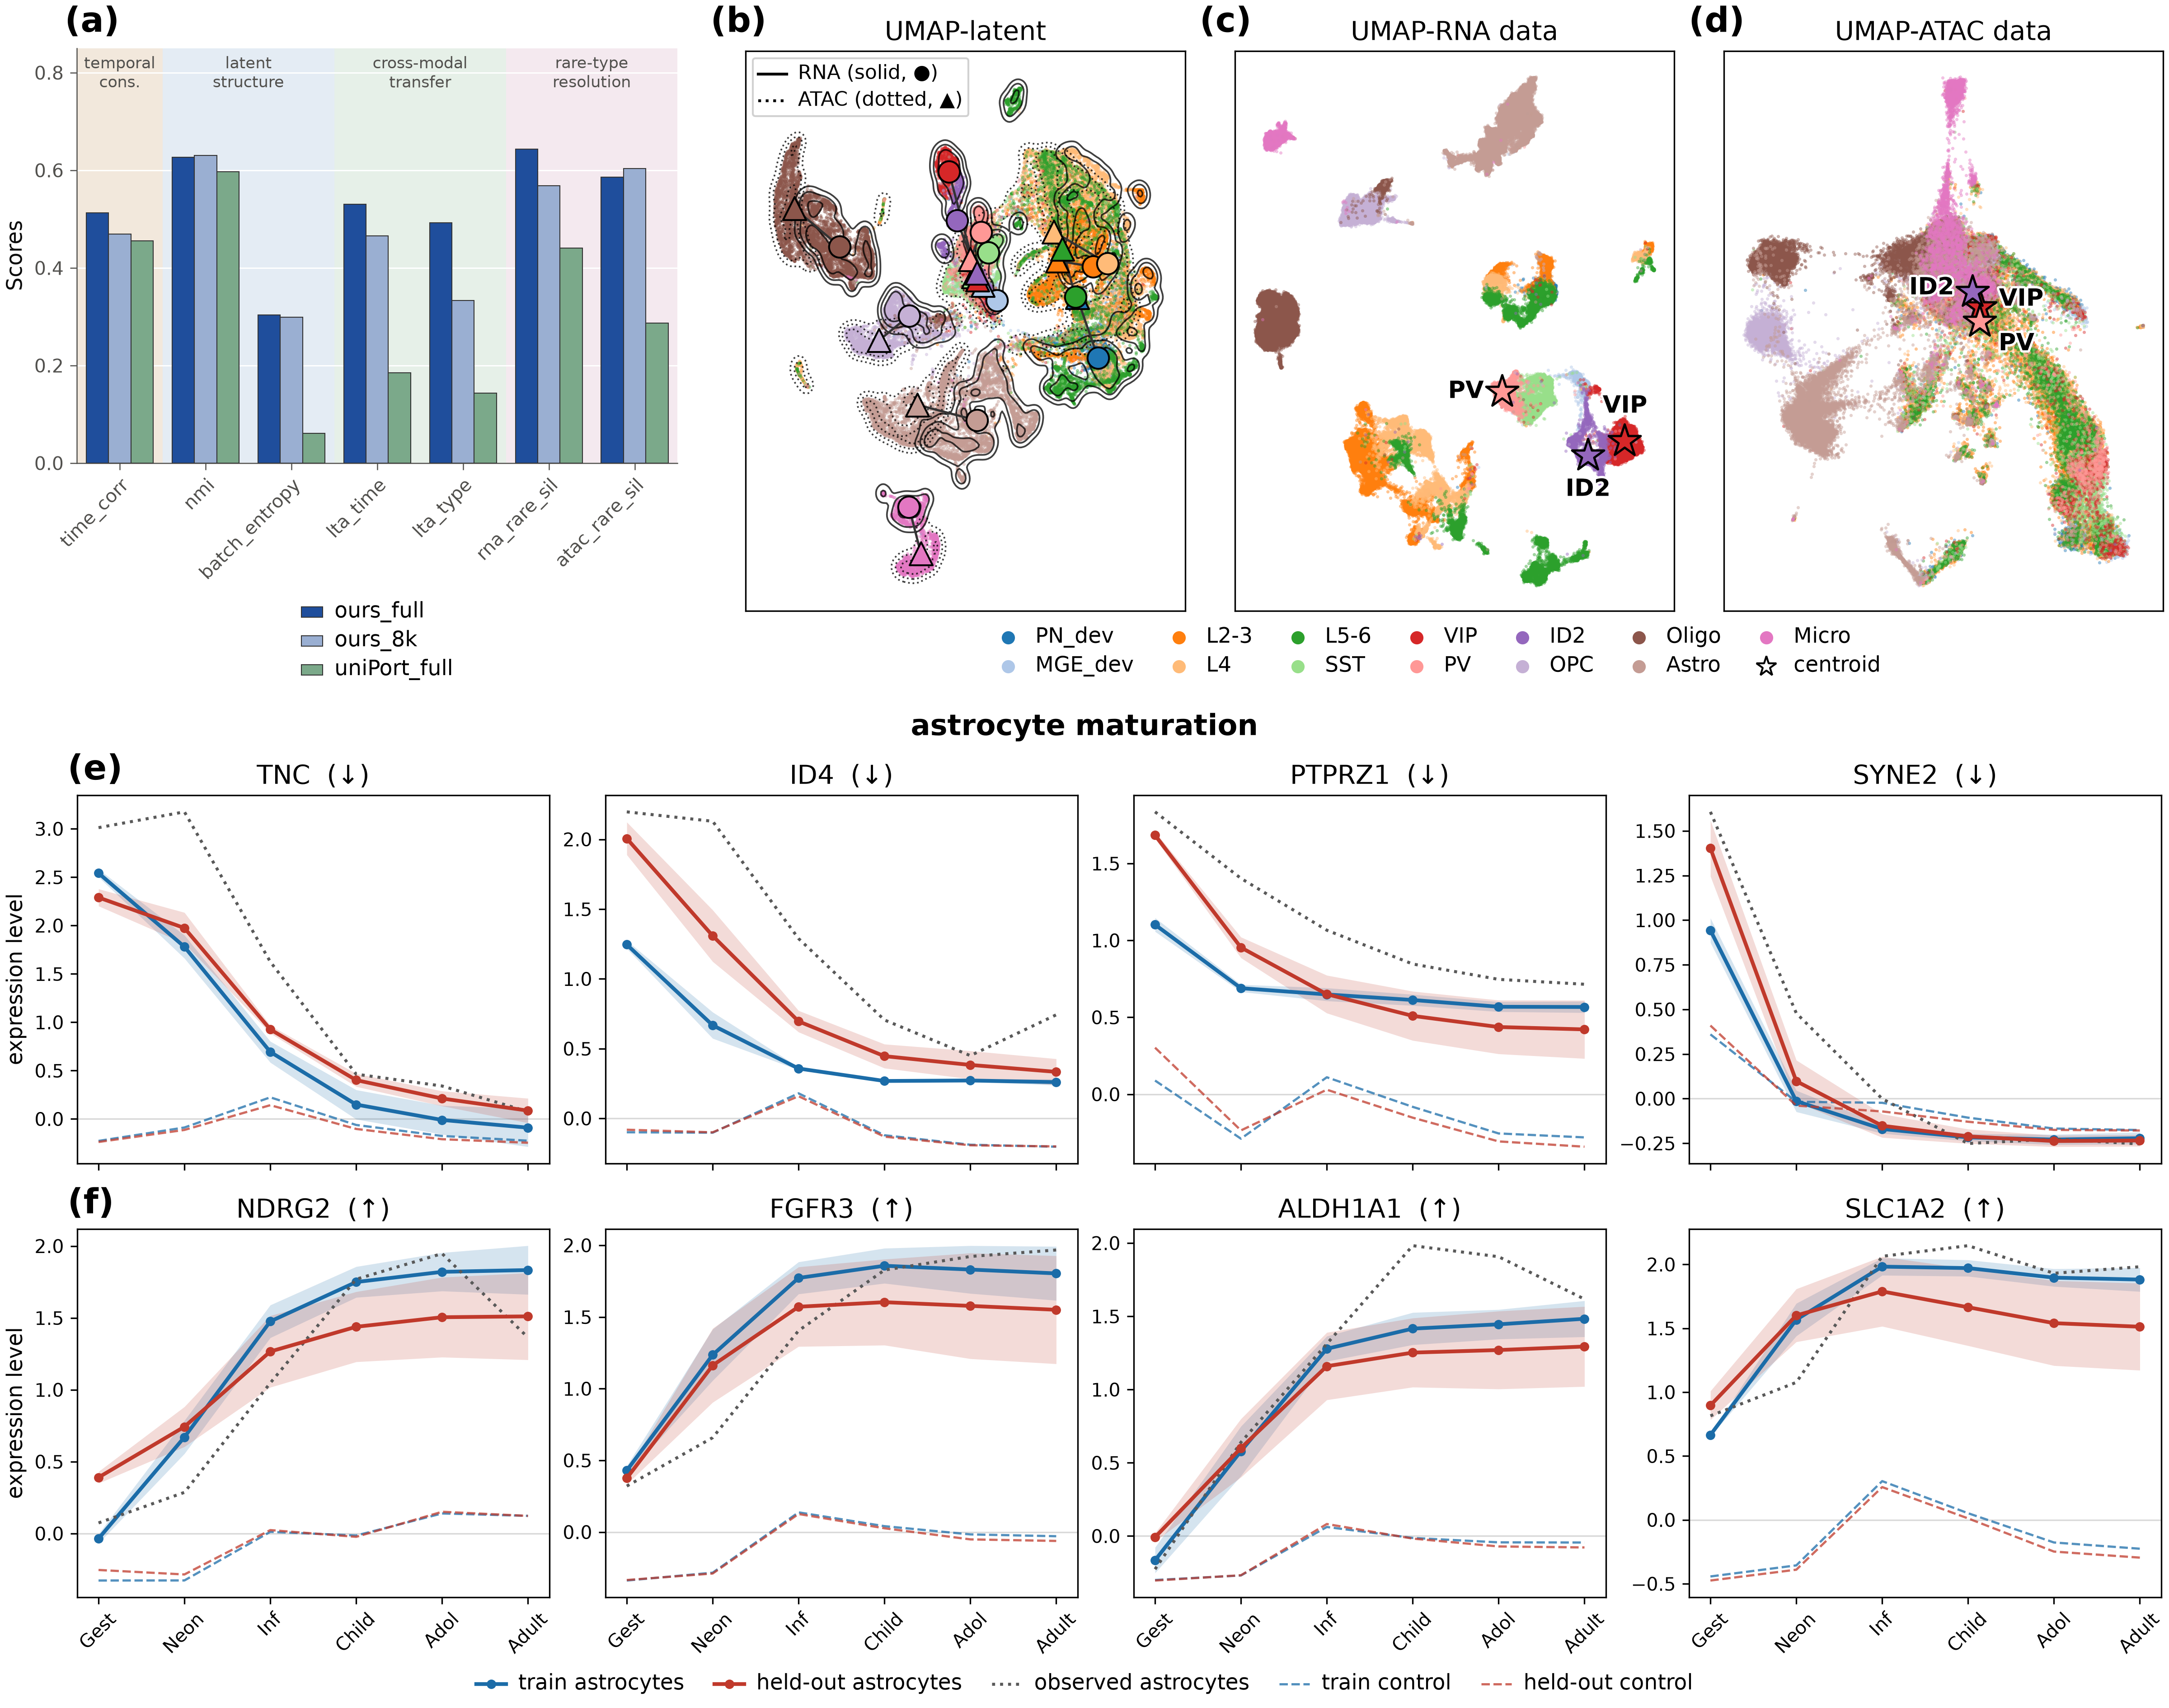

In [2]:
import plot_pfc_composite as pc  # Fig 3's package script

pc.HERE = FIG_DATA  # the module reads every CSV from HERE: point it at the figshare folder
# = python plot_pfc_composite.py --control-cohort rna_only --stem pfc_composite_rnactl
pc.composite_figure(OUT, stem="pfc_composite_rnactl", control_cohort="rna_only")
png = OUT / "pfc_composite_rnactl.png"
display(Image(filename=str(png)))

In [3]:
digest = hashlib.md5(png.read_bytes()).hexdigest()
print(f"{png.name}: md5 {digest}")
print("byte-identical to the paper's PNG (pfc_composite_rnactl.png):", digest == "de02a841f502d6449dec61998a74c1fa")
print("(byte identity needs matplotlib 3.11.1; other versions shift pixels)")

pfc_composite_rnactl.png: md5 de02a841f502d6449dec61998a74c1fa
byte-identical to the paper's PNG (pfc_composite_rnactl.png): True
(byte identity needs matplotlib 3.11.1; other versions shift pixels)


## Table 1: cell types and their cross-modal alignment

The 13 coarse cell types, in the figure's order, with their class. `n_rna` and `n_atac` are the
type's nuclei: every annotated nucleus of the atlas, 149,438 RNA and 83,410 ATAC (the `Other`
nuclei are left out). `cosine_*` is the centred centroid cosine between the type's RNA and ATAC
nuclei in the fused latent, computed on all of them: the mean, sd, min and max over seeds 22, 44
and 88. `starred` marks the three lowest means (VIP, ID2, PV), whose
medoids are starred in (c, d).

In [4]:
display(pd.read_csv(FIG_DATA / "cell_types.csv"))

,cell_type,cell_class,n_rna,n_atac,cosine_mean,cosine_sd,cosine_min,cosine_max,n_seeds,starred
0,PN_dev,progenitor,3827,5065,0.928752,0.022139,0.912794,0.954027,3,False
1,MGE_dev,progenitor,1612,1868,0.964407,0.011570,0.956041,0.977611,3,False
2,L2-3,excitatory,24316,15315,0.881646,0.186653,0.666122,0.990540,3,False
3,L4,excitatory,14668,11443,0.817676,0.098104,0.704680,0.881124,3,False
4,L5-6,excitatory,16558,7892,0.741278,0.046388,0.701416,0.792195,3,False
5,SST,interneuron,7491,4368,0.912054,0.055796,0.849962,0.957988,3,False
6,VIP,interneuron,6868,2451,-0.029219,0.352340,-0.425813,0.247678,3,True
7,PV,interneuron,3848,1927,0.663217,0.298682,0.324650,0.889422,3,True
8,ID2,interneuron,4930,30,0.469482,0.541756,-0.131152,0.921219,3,True
9,OPC,glia,11145,6991,0.983436,0.006056,0.977591,0.989683,3,False


## Rising margins behind (e, f)

One row per seed and side. `rising_margin_rnactl` is the margin of the drawn figure: the
mixed-cohort astrocytes against the RNA-only controls. The other columns are carried, not drawn.

In [5]:
display(pd.read_csv(FIG_DATA / "astro_rnactl_margins.csv"))

,seed,regime,rising_margin_mixed,ctl_delta_rising_mixed,ctl_delta_rising_rna_only,rising_margin_rnactl,rising_margin_rnactl_from_curves
0,22,train,0.668445,0.268275,0.401248,0.535472,0.535475
1,22,heldout,0.214532,0.455037,0.407402,0.262167,0.262125
2,44,train,1.016676,0.292310,0.291596,1.017390,1.017388
3,44,heldout,0.045606,0.405490,0.297743,0.153353,0.153375
4,88,train,0.899131,0.245135,0.287073,0.857193,0.857200
5,88,heldout,0.714423,0.448379,0.186232,0.976570,0.976550
